# 02 · Model benchmark — comparing architectures fairly

**The question:** which kind of model predicts the drag of a Myring hull best — and *why*?

In `01_data_exploration.ipynb` we learned:
- physics alone (friction formula × shape factor) already gets within ~4.7 %;
- every model struggles on **fat hulls (L/d < 7)**, where flow separation adds pressure drag;
- the original paper picked its network using the **test set** (test leakage), so its 1.85 % is optimistic.

In this notebook we compare models under **identical, fair rules**, including a faithful replication of the paper's
network. Later sections (added step by step) test whether **giving a model physics** matters more than its architecture.

### What we test
| ID | Model | Family | Section |
|---|---|---|---|
| M0 | Physics formula (ITTC friction × Hoerner form factor) | no learning | 2 |
| M2 | Gradient-boosted trees | classic ML | 3 |
| M3 | Gaussian process (Matérn kernel) | classic ML | 4 |
| M1 | **The paper's 9-layer network**, replicated without test leakage | neural net | 5 |
| M5 | A small modern MLP (3 layers, smooth activations, log target) | neural net | 6 |
| *later* | Physics-input / physics-target ablation, physics-informed hybrid (M4), deep ensemble (M6), learning curves | SciML | next notebook steps |

---
## 1 · The fair-comparison protocol

All the bookkeeping lives in `models/harness.py`, so every model follows exactly the same rules:

1. **Data:** the 2,400 training hulls. **10 %** of them (240) are set aside as a **validation set** — used only to
   decide *when to stop training*. The 621 **test** hulls are used **once**, at the end, to score.
2. **Seeds:** each model is trained **5 times** with different random seeds (different validation split and
   initial weights). We report the **average ± spread**, so one lucky run cannot fool us.
3. **Metrics:** mean absolute percentage error (**MAPE**) overall and per fineness group (fat / typical / slender /
   very slender), the worst single error, and training time.
4. **Results file:** every run is written to `results/benchmark.csv`, so we can build the final table and README from it.

The picture below shows the flow of data. Run the cell to draw it.

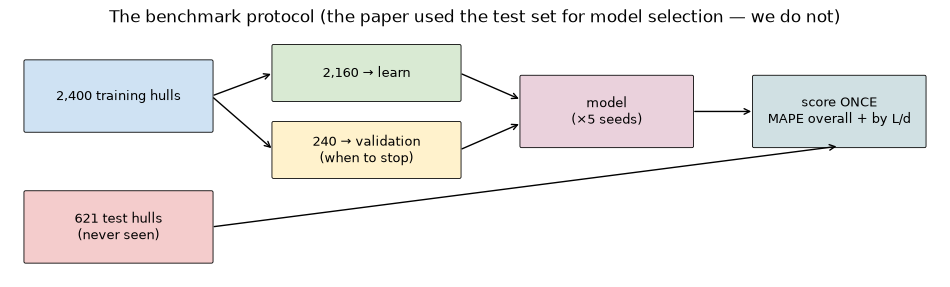

train: (2400, 6)  test: (621, 6)


In [1]:
import sys
sys.path.insert(0, '..')                       # let Python find our 'models' folder
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from models import harness, nets
from models.physics import drag_m0

def box(ax, x, y, w, h, text, color):
    """Draw a rounded box with centred text (used for all diagrams in this notebook)."""
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle='round,pad=0.02', fc=color, ec='k', lw=0.6))
    ax.text(x + w / 2, y + h / 2, text, ha='center', va='center', fontsize=9)

def arrow(ax, x1, y1, x2, y2):
    ax.annotate('', (x2, y2), (x1, y1), arrowprops=dict(arrowstyle='->', lw=1))

fig, ax = plt.subplots(figsize=(12, 3.2)); ax.axis('off'); ax.set_xlim(0, 12); ax.set_ylim(0, 3.2)
box(ax, 0.2, 1.9, 2.4, 0.9, '2,400 training hulls', '#cfe2f3')
box(ax, 3.4, 2.3, 2.4, 0.7, '2,160 → learn', '#d9ead3')
box(ax, 3.4, 1.3, 2.4, 0.7, '240 → validation\n(when to stop)', '#fff2cc')
box(ax, 6.6, 1.7, 2.2, 0.9, 'model\n(×5 seeds)', '#ead1dc')
box(ax, 0.2, 0.2, 2.4, 0.9, '621 test hulls\n(never seen)', '#f4cccc')
box(ax, 9.6, 1.7, 2.2, 0.9, 'score ONCE\nMAPE overall + by L/d', '#d0e0e3')
arrow(ax, 2.6, 2.35, 3.4, 2.65); arrow(ax, 2.6, 2.35, 3.4, 1.65)
arrow(ax, 5.8, 2.65, 6.6, 2.3); arrow(ax, 5.8, 1.65, 6.6, 2.0)
arrow(ax, 8.8, 2.15, 9.6, 2.15); arrow(ax, 2.6, 0.65, 10.7, 1.7)
ax.set_title('The benchmark protocol (the paper used the test set for model selection — we do not)')
plt.show()

X_train, y_train, X_test, y_test = harness.load_data()
print('train:', X_train.shape, ' test:', X_test.shape)

### 1.1 The metric
**MAPE** (mean absolute percentage error): for every test hull compute |prediction − CFD| ÷ CFD × 100, then average.
A MAPE of 2 % means "on average, 2 % off". We also report it **per fineness group**, because the average hides the
fat-hull failures we found in notebook 01.

Every model is plugged in the same way: a function `fit_predict(X_tr, y_tr, X_val, y_val, X_test, seed)` that trains
on the training part, may look at the validation part, and returns predictions for the test hulls.
`harness.run(name, fit_predict)` does the rest (splits, seeds, scoring, saving).

---
## 2 · M0 — the physics formula (no learning)
Drag = ½ρU² × wetted area × ITTC friction coefficient × (1 + Hoerner form factor). See `models/physics.py`.
It ignores the training data completely, so all 5 "seeds" give the same answer — we run it once.

In [2]:
def fit_predict_m0(X_tr, y_tr, X_val, y_val, X_test, seed):
    return np.array([drag_m0(*row) for row in X_test])      # no training: just apply the formula

rows_m0 = harness.run('M0 physics', fit_predict_m0, seeds=(0,))

M0 physics                   seed 0:  4.68 %   fat hulls  18.5 %   (0.0 s)


---
## 3 · M2 — gradient-boosted trees
A **decision tree** splits hulls with if/then rules ("if d > 150 mm and L < 1.2 m then …"). **Boosting** trains
hundreds of small trees one after another, each correcting the errors of the ones before.
Strengths: fast, strong on tabular data, no scaling needed. Weakness: predictions are piecewise constant (step-shaped),
not smooth — not ideal for physics.

In [3]:
from sklearn.ensemble import HistGradientBoostingRegressor

def fit_predict_m2(X_tr, y_tr, X_val, y_val, X_test, seed):
    model = HistGradientBoostingRegressor(max_iter=500, learning_rate=0.05, random_state=seed)
    return model.fit(X_tr, y_tr).predict(X_test)

rows_m2 = harness.run('M2 boosted trees', fit_predict_m2)

M2 boosted trees             seed 0:  3.28 %   fat hulls  15.1 %   (3.4 s)
M2 boosted trees             seed 1:  3.54 %   fat hulls  15.3 %   (3.9 s)
M2 boosted trees             seed 2:  3.34 %   fat hulls  16.0 %   (3.5 s)
M2 boosted trees             seed 3:  3.28 %   fat hulls  14.5 %   (3.7 s)
M2 boosted trees             seed 4:  3.43 %   fat hulls  14.7 %   (3.4 s)


---
## 4 · M3 — Gaussian process
A Gaussian process (GP) predicts a new hull's drag from the training hulls **most similar** to it, weighted by
similarity. The **kernel** defines "similar": the Matérn kernel says nearby hulls have similar drag, with one
**length scale** per input that the GP learns (a short length scale = drag changes quickly with that input).
It also returns an **uncertainty** (± error bar) for each prediction.

We fit **log(drag)** so the GP cares about *relative* errors. Cost grows with the cube of the number of training hulls,
so this cell takes several minutes — it runs **once** (seed 0) to save time.

In [4]:
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern, WhiteKernel, ConstantKernel
from sklearn.preprocessing import StandardScaler

def fit_predict_m3(X_tr, y_tr, X_val, y_val, X_test, seed):
    sx = StandardScaler().fit(X_tr)                               # put all 6 inputs on the same scale
    kernel = ConstantKernel() * Matern(length_scale=np.ones(6), nu=2.5) + WhiteKernel()
    gp = GaussianProcessRegressor(kernel, normalize_y=True, random_state=seed)
    gp.fit(sx.transform(X_tr), np.log(y_tr))
    return np.exp(gp.predict(sx.transform(X_test)))

rows_m3 = harness.run('M3 Gaussian process', fit_predict_m3, seeds=(0,))

M3 Gaussian process          seed 0:  2.06 %   fat hulls  16.6 %   (56.4 s)


---
## 5 · M1 — the paper's network, replicated

### 5.1 What it looks like
A **multilayer perceptron (MLP)** passes the 6 inputs through layers of "neurons". Each neuron computes a weighted
sum of the previous layer and applies an **activation function** (here **ReLU**: keep positive values, set negatives
to 0). Training adjusts the weights to reduce the error.

The paper's network is **deep and oddly shaped**: widths 128 → 64 → 64 → 32 → 32 → 64 → 64 → 8, with a **skip
connection** after the third layer (its output is added to its own ReLU). The cell below draws it.

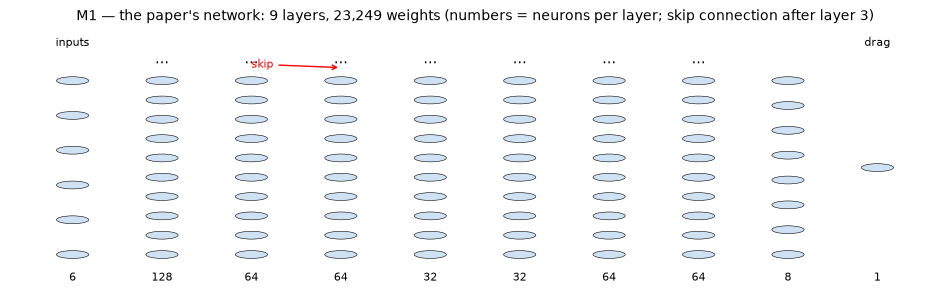

In [5]:
def draw_mlp(ax, widths, title, color='#cfe2f3', max_dots=10):
    """Draw an MLP as columns of dots (one column per layer); big layers are shown with '…' and their size."""
    ax.axis('off')
    for i, w in enumerate(widths):
        shown = min(w, max_dots)
        ys = np.linspace(-1, 1, shown) if shown > 1 else [0]
        for y in ys:
            ax.add_patch(plt.Circle((i, y * 4), 0.18, fc=color, ec='k', lw=0.4))
        ax.text(i, -5.2, str(w), ha='center', fontsize=8)
        if w > max_dots:
            ax.text(i, 4.8, '…', ha='center', fontsize=10)
    ax.text(0, 5.6, 'inputs', ha='center', fontsize=8); ax.text(len(widths) - 1, 5.6, 'drag', ha='center', fontsize=8)
    ax.set_xlim(-0.7, len(widths) - 0.3); ax.set_ylim(-6, 6.4); ax.set_title(title, fontsize=10)

fig, ax = plt.subplots(figsize=(12, 3.5))
draw_mlp(ax, nets.PaperSNet.WIDTHS, f'M1 — the paper\'s network: 9 layers, {nets.n_params(nets.PaperSNet()):,} weights '
         '(numbers = neurons per layer; skip connection after layer 3)')
ax.annotate('skip', (3, 4.6), (2, 4.6), arrowprops=dict(arrowstyle='->', color='red'), color='red', fontsize=8)
plt.show()

### 5.2 How it is trained (as in the paper, but without test leakage)
- Inputs and drag are scaled to 0–1 (**MinMax** scaling), as in their code.
- Loss: **L1** (mean absolute error). Optimiser: **Adam**, learning rate 0.001, batches of 32, up to 400 epochs
  (an *epoch* = one pass over all training hulls).
- We keep the weights with the lowest **validation** loss — the paper used the test set here.

This takes ~1–2 minutes per seed (5 seeds ≈ 5–10 minutes).

In [6]:
from sklearn.preprocessing import MinMaxScaler

def fit_predict_m1(X_tr, y_tr, X_val, y_val, X_test, seed):
    sx, sy = MinMaxScaler().fit(X_tr), MinMaxScaler().fit(y_tr[:, None])
    model = nets.train(nets.PaperSNet(), sx.transform(X_tr), sy.transform(y_tr[:, None]),
                       sx.transform(X_val), sy.transform(y_val[:, None]),
                       loss='l1', epochs=EPOCHS_M1, lr=1e-3, batch=32, seed=seed)
    return sy.inverse_transform(nets.predict(model, sx.transform(X_test))).ravel()

EPOCHS_M1 = 400
rows_m1 = harness.run('M1 paper network', fit_predict_m1)

M1 paper network             seed 0: 40.14 %   fat hulls  29.7 %   (25.9 s)
M1 paper network             seed 1:  2.20 %   fat hulls  16.2 %   (25.7 s)
M1 paper network             seed 2:  2.04 %   fat hulls  15.8 %   (23.3 s)
M1 paper network             seed 3:  1.84 %   fat hulls  13.1 %   (22.5 s)
M1 paper network             seed 4:  2.17 %   fat hulls  13.4 %   (27.5 s)


---
## 6 · M5 — a small, modern MLP
Is the paper's 9-layer design necessary? Here is a **much smaller** network trained with today's standard choices:

| Choice | Paper (M1) | Modern (M5) | Why |
|---|---|---|---|
| Size | 9 layers, ~23k weights | 3 layers × 64, ~9k weights | smaller = less overfitting on 2,400 examples |
| Activation | ReLU (kinked) | **SiLU** (smooth) | physics is smooth; smooth networks fit it better |
| Target | drag scaled 0–1 | **log(drag)**, standardised | errors become *relative*; drag spans 0.5–21 N |
| Inputs | MinMax 0–1 | standardised (mean 0, std 1) | standard practice |
| Loss | L1 | MSE on log(drag) | smooth, works well with log target |
| Optimiser | Adam | **AdamW** + weight decay, early stopping | mild regularisation, stops when validation stops improving |

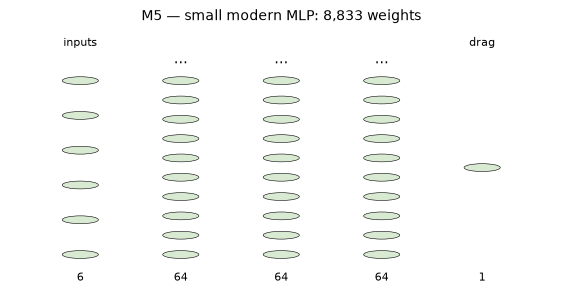

M5 small modern MLP          seed 0:  2.74 %   fat hulls  16.0 %   (2.4 s)
M5 small modern MLP          seed 1:  3.50 %   fat hulls  17.8 %   (1.1 s)
M5 small modern MLP          seed 2:  2.90 %   fat hulls  17.0 %   (3.1 s)
M5 small modern MLP          seed 3:  3.11 %   fat hulls  17.4 %   (1.2 s)
M5 small modern MLP          seed 4:  3.54 %   fat hulls  19.4 %   (1.4 s)


In [7]:
fig, ax = plt.subplots(figsize=(7, 3.5))
draw_mlp(ax, [6, 64, 64, 64, 1], f'M5 — small modern MLP: {nets.n_params(nets.SimpleMLP()):,} weights', color='#d9ead3')
plt.show()

def fit_predict_m5(X_tr, y_tr, X_val, y_val, X_test, seed):
    sx = StandardScaler().fit(X_tr)
    ly = np.log(y_tr); mu, sd = ly.mean(), ly.std()                # standardise log(drag)
    model = nets.train(nets.SimpleMLP(), sx.transform(X_tr), ((ly - mu) / sd)[:, None],
                       sx.transform(X_val), ((np.log(y_val) - mu) / sd)[:, None],
                       loss='mse', epochs=EPOCHS_M5, lr=3e-3, batch=64, weight_decay=1e-4, patience=60, seed=seed)
    return np.exp(nets.predict(model, sx.transform(X_test)).ravel() * sd + mu)

EPOCHS_M5 = 800
rows_m5 = harness.run('M5 small modern MLP', fit_predict_m5)

---
## 7 · Results

In [8]:
table = harness.summary()
cols = [('mape', 'overall'), ('mape_fat', 'fat'), ('mape_typical', 'typical'), ('mape_slender', 'slender'),
        ('mape_very_slender', 'v. slender'), ('max_err', 'worst'), ('train_seconds', 'time (s)')]
print(f'{"model":24s}' + ''.join(f'{lab:>16s}' for _, lab in cols))
for model, vals in table.items():
    print(f'{model:24s}' + ''.join(f'{vals[c][0]:9.2f} ±{vals[c][1]:5.2f}' for c, _ in cols))
print('\npaper\'s reported network error (with test leakage): 1.85 %')

model                            overall             fat         typical         slender      v. slender           worst        time (s)
M0 physics                   4.68 ± 0.00    18.55 ± 0.00     3.79 ± 0.00     3.41 ± 0.00     3.21 ± 0.00    72.45 ± 0.00     0.05 ± 0.00
M2 boosted trees             3.37 ± 0.10    15.11 ± 0.52     3.63 ± 0.20     1.79 ± 0.09     1.71 ± 0.06    65.03 ± 3.69     3.56 ± 0.18
M3 Gaussian process          2.06 ± 0.00    16.62 ± 0.00     0.97 ± 0.00     0.56 ± 0.00     0.87 ± 0.00   182.33 ± 0.00    56.36 ± 0.00
M1 paper network             9.68 ±15.23    17.63 ± 6.14     6.11 ± 9.36     6.79 ±12.32    14.64 ±27.50   105.87 ±60.77    24.98 ± 1.83
M5 small modern MLP          3.16 ± 0.32    17.51 ± 1.13     3.15 ± 0.65     1.33 ± 0.18     1.32 ± 0.12    69.03 ± 8.98     1.86 ± 0.76

paper's reported network error (with test leakage): 1.85 %


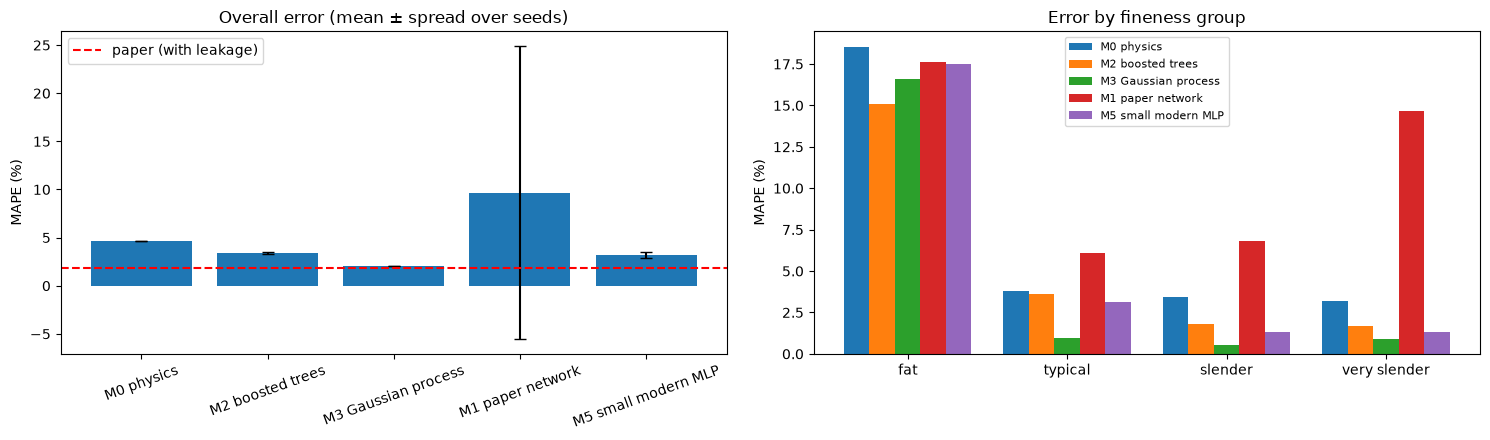

In [9]:
names = list(table)
groups = [('mape_fat', 'fat'), ('mape_typical', 'typical'), ('mape_slender', 'slender'), ('mape_very_slender', 'very slender')]
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
ax[0].bar(names, [table[m]['mape'][0] for m in names], yerr=[table[m]['mape'][1] for m in names], capsize=4)
ax[0].axhline(1.85, ls='--', c='red', label='paper (with leakage)'); ax[0].legend()
ax[0].set(ylabel='MAPE (%)', title='Overall error (mean ± spread over seeds)'); ax[0].tick_params(axis='x', rotation=20)
w = 0.8 / len(names)
for k, m in enumerate(names):
    ax[1].bar(np.arange(4) + k * w, [table[m][g][0] for g, _ in groups], w, label=m)
ax[1].set_xticks(np.arange(4) + 0.4 - w / 2, [lab for _, lab in groups])
ax[1].set(ylabel='MAPE (%)', title='Error by fineness group'); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

### ✍️ Questions
1. Does the paper's 9-layer network (M1) beat the small modern MLP (M5)? Is the extra depth worth it?
2. Which model is best overall? Which is best on **fat** hulls? Are they the same model?
3. How big is the **spread** between seeds for the neural networks? What does that mean for comparing two models whose
   averages differ by 0.1 %?
4. Every model still fails on fat hulls. Based on notebook 01, what could we *give* a model to help it there?
   (This is what the next sections — physics inputs, physics targets, and the hybrid M4 — will test.)

---
### Next steps (added after you've worked through this)
- **Ablation:** same MLP with raw vs physics inputs × predicting drag vs predicting the correction over M0.
- **M4:** the physics-informed hybrid (dimensionless inputs + correction target + physics constraints).
- **M6:** deep ensemble (5 MLPs averaged) for uncertainty.
- **Learning curves:** how each model's error falls with 50 → 2,400 training hulls.

---
## Replication check: our results vs the paper

The paper reports **≈ 1.85 % MAPE** for its network (see `knowledge/01-paper.md`).
Their code trained 5 times and kept the run that scored best **on the test set**. We compute our M1 number two ways:
- **Paper protocol:** the best of our 5 seeds, scored on the test set. This copies their selection, leakage included.
- **Fair protocol:** the mean ± std over the 5 seeds, each chosen on validation only. This is what a new user would actually get.

In [ ]:
import csv, statistics as st
PAPER_MAPE = 1.85
rows = list(csv.DictReader(open('../results/benchmark.csv')))
m1 = [float(x['mape']) for x in rows if x['model'].startswith('M1')]
print(f'Paper (reported)                : {PAPER_MAPE:.2f} %')
print(f'Ours, paper protocol (best of 5): {min(m1):.2f} %   -> difference {min(m1) - PAPER_MAPE:+.2f} points')
print(f'Ours, fair protocol (mean ± std): {st.mean(m1):.2f} ± {st.stdev(m1):.2f} %')
print(f'Ours, median of 5 seeds         : {st.median(m1):.2f} %')
print(f'Collapsed seeds (> 10 %)        : {sum(v > 10 for v in m1)} of {len(m1)}')
print()
print('Other models, fair protocol:')
for name in dict.fromkeys(x['model'] for x in rows):
    print(f'   {name:38s} {st.mean(float(x["mape"]) for x in rows if x["model"] == name):5.2f} %')